# FactoryMind AI — Anomaly Detection (LSTM Autoencoder)
Trains an LSTM Autoencoder on *normal* sensor sequences only, then uses reconstruction error to flag abnormal behavior.

In [1]:
import sys
sys.path.insert(0, '../src')
import warnings; warnings.filterwarnings('ignore')
from anomaly_model import train
model, scaler, threshold, metrics = train()
metrics

I0000 00:00:1789711446.211705     218 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789711463.302073     218 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1789711469.833454     218 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


E0000 00:00:1789711475.535993     218 util.cc:131] oneDNN supports DT_INT32 only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


Anomaly model trained: {'threshold': 0.26413, 'roc_auc': 1.0, 'precision': 0.875, 'recall': 1.0, 'f1': 0.9333, 'n_train_normal_sequences': 510}


{'threshold': 0.26413,
 'roc_auc': 1.0,
 'precision': 0.875,
 'recall': 1.0,
 'f1': 0.9333,
 'n_train_normal_sequences': 510}

## Reconstruction error distribution

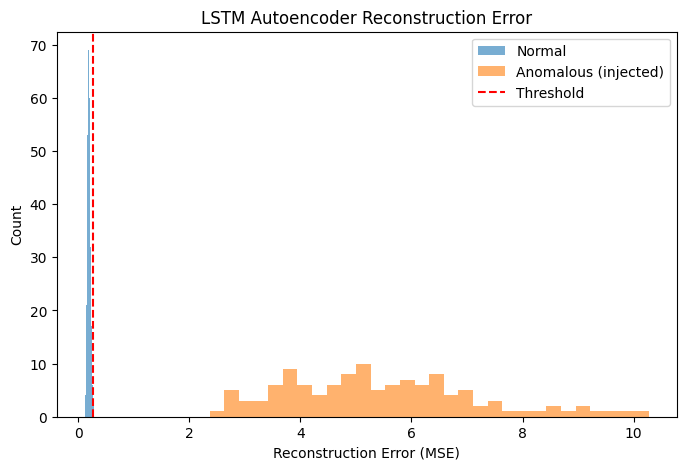

In [2]:
import joblib, numpy as np
import matplotlib.pyplot as plt

eval_data = joblib.load('../models/anomaly_eval.pkl')
errors = np.array(eval_data['all_errors'])
labels = np.array(eval_data['labels'])

plt.figure(figsize=(8,5))
plt.hist(errors[labels==0], bins=30, alpha=0.6, label='Normal')
plt.hist(errors[labels==1], bins=30, alpha=0.6, label='Anomalous (injected)')
plt.axvline(threshold, color='red', linestyle='--', label='Threshold')
plt.xlabel('Reconstruction Error (MSE)'); plt.ylabel('Count')
plt.legend(); plt.title('LSTM Autoencoder Reconstruction Error')
plt.show()

## Scoring a single sequence

In [3]:
from preprocessing import load_anomaly_sequences
from anomaly_model import score_sequence

seqs, labs, feature_names = load_anomaly_sequences('../data/anomaly_sequences.npz')
anomaly_idx = np.where(labs == 1)[0][0]
score_sequence(model, scaler, threshold, seqs[anomaly_idx], feature_names)

{'anomaly_score_pct': 100.0,
 'reconstruction_error': 8.40476,
 'threshold': 0.26413,
 'status': 'CRITICAL',
 'feature_contributions': {np.str_('Temperature'): 20.9,
  np.str_('Vibration'): 67.5,
  np.str_('Pressure'): 0.9,
  np.str_('Rotational_Speed'): 0.6,
  np.str_('Torque'): 10.1}}

In [4]:
normal_idx = np.where(labs == 0)[0][0]
score_sequence(model, scaler, threshold, seqs[normal_idx], feature_names)

{'anomaly_score_pct': 28.4,
 'reconstruction_error': 0.1876,
 'threshold': 0.26413,
 'status': 'NORMAL',
 'feature_contributions': {np.str_('Temperature'): 14.4,
  np.str_('Vibration'): 11.5,
  np.str_('Pressure'): 20.5,
  np.str_('Rotational_Speed'): 25.9,
  np.str_('Torque'): 27.6}}

## Takeaway
The model, trained only on normal behavior, assigns high reconstruction error to the injected anomalous bursts (temperature/vibration/torque spikes) and low error to normal sequences — confirming it has learned what 'normal' looks like rather than memorizing labels.